# アウトカム再定義 Step 1：ARIS care 記載の抽出と非該当例のキーワード候補洗い出し

- 母集団：`unex_study` 1,281例（固定）
- 対象テキスト：`karte.karte_text` のみ（医師・看護の両記録、区別列あり）
- 時間窓：死亡当日を含む10日間（死亡日−9日〜死亡日、日単位近似）
- 照合：NFKC正規化（全角→半角）後、大文字小文字を区別せず ARIS / RIS / アリス を抽出
- 「予定」：同一記録内フラグと、一致箇所の前後近傍フラグの2種
- 出力（utf-8-sig）：`/Users/muna/Hana_research/data/output/outcome_redef/`
  1. `01_aris_hits_long.csv` 一致1件1行
  2. `02_aris_patient_summary.csv` 患者1行（1,281行）
  3. `03_nonaris_window_records.csv` ARIS非該当例の窓内全記録
  4. `04_nonaris_ngram_df.csv` 非該当例の頻出文字n-gram（患者単位の出現数）
- DBは読み取りのみ。書き込みはしない。

In [1]:
import sqlite3
import re
import unicodedata
from pathlib import Path
from collections import Counter

import pandas as pd

DB_PATH = "/Users/muna/Hana_research/data/db/Hana_Research.db"
OUT_DIR = Path("/Users/muna/Hana_research/data/output/outcome_redef")
OUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_DAYS = 10          # 死亡当日を含む日数（0〜9日前）
CONTEXT_CHARS = 40        # 一致箇所の前後に切り出す文字数
YOTEI_NEAR_CHARS = 20     # 「予定」を近傍とみなす前後文字数
NGRAM_MIN, NGRAM_MAX = 2, 6
NGRAM_MIN_PATIENTS = 5    # n-gram出力の下限（非該当群で出現した患者数）
NGRAM_TOP = 30000         # n-gram出力の上限行数

# 非該当群の判定に使う語（RISの誤一致が多ければここから外す）
TERMS_FOR_GROUPING = ["ARIS", "RIS", "アリス"]

con = sqlite3.connect(DB_PATH)

## 1. 母集団・死亡日・初回判定ラベル

In [2]:
PID = "CAST(CAST({col} AS INTEGER) AS TEXT)"   # Patient_IDの型・表記を統一

pop = pd.read_sql(f"""
    SELECT {PID.format(col='Patient_ID')} AS Patient_ID, Study_ID, Unex_48
    FROM unex_study
""", con)
print("unex_study rows:", len(pop), "/ unique Patient_ID:", pop.Patient_ID.nunique())

orig = pd.read_sql(f"""
    SELECT {PID.format(col='Patient_ID')} AS Patient_ID, unex24
    FROM unexpected_death
""", con)
print("unexpected_death rows:", len(orig), "/ unique:", orig.Patient_ID.nunique())
dup_orig = orig[orig.duplicated("Patient_ID", keep=False)]
if len(dup_orig):
    print("unexpected_death に重複あり（要確認）:"); display(dup_orig.sort_values("Patient_ID"))
orig = orig.drop_duplicates("Patient_ID")

ev = pd.read_sql(f"""
    SELECT {PID.format(col='Patient_ID')} AS Patient_ID, death_date
    FROM event
    WHERE death_date IS NOT NULL AND TRIM(death_date) <> ''
""", con)
print("death_date 表記サンプル:", ev.death_date.head(5).tolist())

n_conflict = ev.groupby("Patient_ID").death_date.nunique()
n_conflict = n_conflict[n_conflict > 1]
print("death_date が複数値の患者数:", len(n_conflict))
assert len(n_conflict) == 0, "死亡日が複数ある患者がいる。先に確認すること"
ev = ev.drop_duplicates("Patient_ID")

ev["death_dt"] = pd.to_datetime(ev.death_date, errors="coerce").dt.normalize()
print("death_date 変換失敗:", ev.death_dt.isna().sum())

pop = (pop.merge(ev[["Patient_ID", "death_date", "death_dt"]], on="Patient_ID", how="left")
          .merge(orig, on="Patient_ID", how="left"))
print("死亡日なし:", pop.death_dt.isna().sum(), "/ unex24なし:", pop.unex24.isna().sum())
print(pop.unex24.value_counts(dropna=False))

unex_study rows: 1281 / unique Patient_ID: 1281
unexpected_death rows: 1557 / unique: 1557
death_date 表記サンプル: ['2025-12-01', '2026-01-24', '2025-11-30', '2025-12-03', '2026-02-08']
death_date が複数値の患者数: 0
death_date 変換失敗: 0
死亡日なし: 0 / unex24なし: 1
unex24
0.0    1041
1.0     239
NaN       1
Name: count, dtype: int64


## 2. visit_type の確認（医師／看護の区別に使う）

In [3]:
vt = pd.read_sql("""
    SELECT visit_type,
           COUNT(*) AS n_records,
           SUM(CASE WHEN nurse_name IS NOT NULL AND TRIM(nurse_name) <> '' THEN 1 ELSE 0 END) AS n_with_nurse_name
    FROM karte
    GROUP BY visit_type
    ORDER BY n_records DESC
""", con)
display(vt)

,visit_type,n_records,n_with_nurse_name
0,定期訪問,157799,147144
1,外来,60696,3083
2,電話再診,42275,25387
3,その他,40364,4999
4,文書,35455,6776
5,予防接種,22693,6601
6,訪問看護,11548,11115
7,自費,8583,655
8,緊急往診,8348,7252
9,訪問リハ(介護),8262,7502


## 3. 対象患者のカルテ読み込みと時間窓

In [6]:
con.execute("DROP TABLE IF EXISTS temp.pop_ids")
con.execute("CREATE TEMP TABLE pop_ids (Patient_ID TEXT PRIMARY KEY)")
con.executemany("INSERT INTO pop_ids VALUES (?)", [(i,) for i in pop.Patient_ID])

k = pd.read_sql(f"""
    SELECT {PID.format(col='k.Patient_ID')} AS Patient_ID,
           k.record_no, k.visit_type, k.visit_datetime, k.facility,
           CASE WHEN k.nurse_name IS NOT NULL AND TRIM(k.nurse_name) <> '' THEN 1 ELSE 0 END AS has_nurse_name,
           k.karte_text
    FROM karte k
    JOIN temp.pop_ids p ON {PID.format(col='k.Patient_ID')} = p.Patient_ID
""", con)
print("読み込んだ記録数:", len(k), "/ 患者数:", k.Patient_ID.nunique())

# ---- 日時の変換（時刻不正は日付のみ採用してフラグ） ----
DT_RE = re.compile(r"(\d{4})/(\d{1,2})/(\d{1,2})(?:\D*(\d{1,2}):(\d{2}))?")

def parse_dt(s):
    if not isinstance(s, str):
        return pd.NaT, 0
    m = DT_RE.search(s)
    if not m:
        return pd.NaT, 0
    y, mo, d, h, mi = m.groups()
    try:
        base = pd.Timestamp(int(y), int(mo), int(d))
    except ValueError:
        return pd.NaT, 0
    if h is None:
        return base, 0
    h, mi = int(h), int(mi)
    if 0 <= h <= 23 and 0 <= mi <= 59:
        return base + pd.Timedelta(hours=h, minutes=mi), 0
    return base, 1

parsed = k.visit_datetime.map(parse_dt)
k["visit_dt"] = pd.to_datetime(parsed.map(lambda x: x[0]))
k["time_invalid"] = parsed.map(lambda x: x[1]).astype(int)
k["time_missing"] = ~k.visit_datetime.fillna("").str.contains(r"\d{1,2}:\d{2}")

print("日付の変換失敗:", k.visit_dt.isna().sum())
display(k.loc[k.visit_dt.isna(), "visit_datetime"].value_counts().head(10))
print("時刻が不正な記録:", k.time_invalid.sum())
display(k.loc[k.time_invalid == 1, "visit_datetime"].value_counts().head(10))

# ---- 死亡日との差と時間窓 ----
k = k.merge(pop[["Patient_ID", "Study_ID", "death_dt"]], on="Patient_ID", how="left")
k["visit_date"] = k.visit_dt.dt.normalize()
k["days_before_death"] = (k.death_dt - k.visit_date).dt.days

print("死亡日より後の記録:", (k.days_before_death < 0).sum())
win = k[(k.days_before_death >= 0) & (k.days_before_death <= WINDOW_DAYS - 1)].copy()
print(f"窓内記録数（{WINDOW_DAYS}日）:", len(win), "/ 患者数:", win.Patient_ID.nunique(),
      "/ 窓内記録なし患者:", len(pop) - win.Patient_ID.nunique())

読み込んだ記録数: 115566 / 患者数: 1281
日付の変換失敗: 0


Series([], Name: count, dtype: int64)

時刻が不正な記録: 2


visit_datetime
2016/1/25(月) 80:20    1
2022/7/22(金) 24:00    1
Name: count, dtype: int64

死亡日より後の記録: 437
窓内記録数（10日）: 7006 / 患者数: 1059 / 窓内記録なし患者: 222


## 4. ARIS / RIS / アリス の抽出

In [7]:
def norm(t):
    return unicodedata.normalize("NFKC", t) if isinstance(t, str) else ""

# 前が英字でない、後ろが英字でない（ただし直後の care は許容）
PATTERNS = {
    "ARIS":  re.compile(r"(?<![A-Za-z])ARIS(?=care|[^A-Za-z]|$)", re.I),
    "RIS":   re.compile(r"(?<![A-Za-z])RIS(?=care|[^A-Za-z]|$)", re.I),
    "アリス": re.compile(r"アリス"),
}
YOTEI = re.compile(r"予定")

win["text_norm"] = win.karte_text.map(norm)

rows = []
for r in win.itertuples(index=False):
    t = r.text_norm
    yotei_in_record = bool(YOTEI.search(t))
    for term, pat in PATTERNS.items():
        for m in pat.finditer(t):
            s, e = m.start(), m.end()
            near = t[max(0, s - YOTEI_NEAR_CHARS): e + YOTEI_NEAR_CHARS]
            rows.append({
                "Study_ID": r.Study_ID, "Patient_ID": r.Patient_ID,
                "death_date": r.death_dt.date(), "record_no": r.record_no,
                "visit_datetime": r.visit_datetime, "visit_date": r.visit_date.date(),
                "days_before_death": r.days_before_death, "time_missing": r.time_missing,
                "visit_type": r.visit_type, "has_nurse_name": r.has_nurse_name,
                "term": term, "matched": m.group(0),
                "context": t[max(0, s - CONTEXT_CHARS): e + CONTEXT_CHARS].replace("\n", " / "),
                "yotei_in_record": int(yotei_in_record),
                "yotei_near": int(bool(YOTEI.search(near))),
                "karte_text": r.karte_text,
            })

hits = pd.DataFrame(rows)
print("一致件数:", len(hits))
if len(hits):
    display(hits.groupby("term").agg(n_hits=("record_no", "size"),
                                     n_records=("record_no", "nunique"),
                                     n_patients=("Patient_ID", "nunique"),
                                     n_yotei_near=("yotei_near", "sum")))
hits.to_csv(OUT_DIR / "01_aris_hits_long.csv", index=False, encoding="utf-8-sig")

一致件数: 686


,n_hits,n_records,n_patients,n_yotei_near
term,,,,
ARIS,659,499,349,13
RIS,8,8,5,0
アリス,19,17,5,0


## 5. 患者単位のまとめ（1,281行）

In [8]:
n_win = win.groupby("Patient_ID").size().rename("n_records_in_window")

def summarize(h, prefix):
    if len(h) == 0:
        return pd.DataFrame(columns=[f"{prefix}_n_records", f"{prefix}_first_date", f"{prefix}_first_days_before_death"])
    first = h.sort_values(["visit_date", "visit_datetime"]).groupby("Patient_ID").first()
    return pd.DataFrame({
        f"{prefix}_n_records": h.groupby("Patient_ID").record_no.nunique(),
        f"{prefix}_first_date": first.visit_date,
        f"{prefix}_first_days_before_death": first.days_before_death,
    })

grp_hits = hits[hits.term.isin(TERMS_FOR_GROUPING)] if len(hits) else hits
summ = pop[["Study_ID", "Patient_ID", "death_date", "unex24", "Unex_48"]].set_index("Patient_ID")
summ = summ.join(n_win).join(summarize(grp_hits, "any"))
summ = summ.join(summarize(grp_hits[grp_hits.yotei_near == 0] if len(grp_hits) else grp_hits, "nonyotei"))
for term in PATTERNS:
    summ = summ.join(summarize(hits[hits.term == term] if len(hits) else hits, term)[[f"{term}_n_records"]])

summ["n_records_in_window"] = summ.n_records_in_window.fillna(0).astype(int)
num_cols = [c for c in summ.columns if c.endswith("_n_records")]
summ[num_cols] = summ[num_cols].fillna(0).astype(int)
summ["aris_any"] = (summ.any_n_records > 0).astype(int)
summ["aris_nonyotei"] = (summ.nonyotei_n_records > 0).astype(int)
summ = summ.reset_index()

print(len(summ), "例")
print("\n初回判定(unex24) × 今回ARIS抽出(any)")
display(pd.crosstab(summ.unex24, summ.aris_any, margins=True))
print("\n初回判定(unex24) × 今回ARIS抽出(予定近傍を除く)")
display(pd.crosstab(summ.unex24, summ.aris_nonyotei, margins=True))

summ.to_csv(OUT_DIR / "02_aris_patient_summary.csv", index=False, encoding="utf-8-sig")

1281 例

初回判定(unex24) × 今回ARIS抽出(any)


aris_any,0,1,All
unex24,,,
0.0,696,345,1041
1.0,232,7,239
All,928,352,1280



初回判定(unex24) × 今回ARIS抽出(予定近傍を除く)


aris_nonyotei,0,1,All
unex24,,,
0.0,702,339,1041
1.0,233,6,239
All,935,345,1280


窓を決めるための「最初の記載」と「死亡直前の最後の記載」

全期間でARISあり × 初回判定


aris_ever,0,1,All
unex24,,,
0.0,652,389,1041
1.0,230,9,239
All,882,398,1280


2017年11月以降の死亡に限定


aris_ever,0,1,All
unex24,,,
0.0,533,387,920
1.0,212,9,221
All,745,396,1141



aris_first_days（ARISあり例のみ）


,count,mean,std,min,10%,25%,50%,75%,90%,max
unex24,,,,,,,,,,
0.0,389.0,74.9,214.7,0.0,1.0,3.0,9.0,31.0,165.0,1827.0
1.0,9.0,263.1,407.0,0.0,0.0,1.0,25.0,308.0,924.8,1012.0



aris_last_days（ARISあり例のみ）


,count,mean,std,min,10%,25%,50%,75%,90%,max
unex24,,,,,,,,,,
0.0,389.0,15.7,115.9,0.0,0.0,1.0,3.0,5.0,11.0,1696.0
1.0,9.0,37.0,101.7,0.0,0.0,1.0,2.0,4.0,72.0,308.0


,window_days(X),last_within_X_all,last_within_X_unex0,last_within_X_unex1,first_within_X_all,last_within_X_%_of_aris
0,0,49,47,2,26,12.3
1,1,134,131,3,56,33.7
2,2,188,183,5,84,47.2
3,3,236,230,6,108,59.3
4,5,300,293,7,149,75.4
5,7,341,334,7,185,85.7
6,10,356,349,7,212,89.4
7,14,376,368,8,241,94.5
8,21,382,374,8,271,96.0
9,30,386,378,8,296,97.0


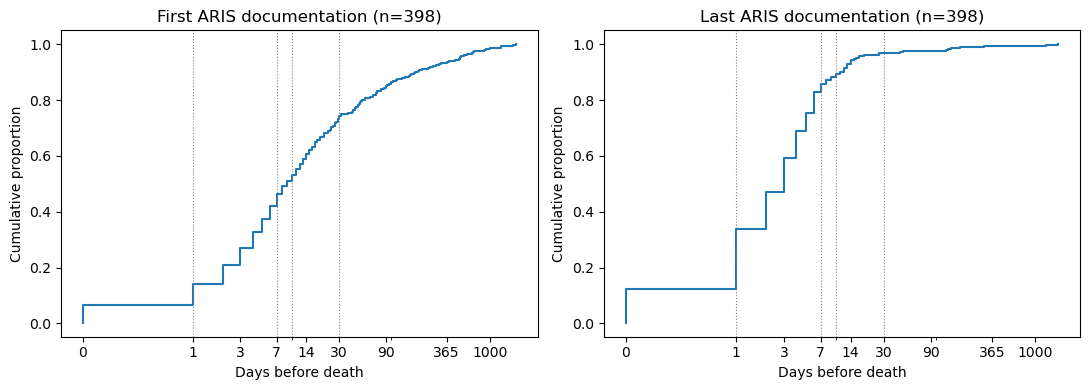

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ---- 死亡日以前の全期間からARIS記載を抽出 ----
pat_all = re.compile("|".join(f"(?:{p.pattern})" for p in PATTERNS.values()), re.I)

allk = k[k.days_before_death >= 0].copy()
allk["t"] = allk.karte_text.map(norm)
allk = allk[allk.t.str.contains(pat_all, regex=True)].copy()
allk["yotei_in_record"] = allk.t.str.contains("予定").astype(int)

def first_last(df, label):
    g = df.groupby("Patient_ID").days_before_death
    return pd.DataFrame({f"{label}_first_days": g.max(),
                         f"{label}_last_days": g.min(),
                         f"{label}_n_records": df.groupby("Patient_ID").record_no.nunique()})

fl = first_last(allk, "aris").join(
     first_last(allk[allk.yotei_in_record == 0], "aris_noyotei"), how="left")

dist = (pop[["Study_ID", "Patient_ID", "death_dt", "unex24"]]
        .merge(fl.reset_index(), on="Patient_ID", how="left"))
dist["aris_ever"] = dist.aris_first_days.notna().astype(int)
dist["death_after_2017_11"] = (dist.death_dt >= "2017-11-01").astype(int)

print("全期間でARISあり × 初回判定")
display(pd.crosstab(dist.unex24, dist.aris_ever, margins=True))
print("2017年11月以降の死亡に限定")
d17 = dist[dist.death_after_2017_11 == 1]
display(pd.crosstab(d17.unex24, d17.aris_ever, margins=True))

# ---- 分布の要約 ----
for col in ["aris_first_days", "aris_last_days"]:
    print(f"\n{col}（ARISあり例のみ）")
    display(dist.groupby("unex24")[col].describe(percentiles=[.1, .25, .5, .75, .9]).round(1))

# ---- 閾値ごとの累積人数：最後の記載が死亡X日前以内（=窓X日なら該当） ----
TH = [0, 1, 2, 3, 5, 7, 10, 14, 21, 30, 60, 90, 180, 365]
has = dist[dist.aris_ever == 1]
cum = pd.DataFrame({
    "window_days(X)": TH,
    "last_within_X_all":    [(has.aris_last_days <= x).sum() for x in TH],
    "last_within_X_unex0":  [((has.aris_last_days <= x) & (has.unex24 == 0)).sum() for x in TH],
    "last_within_X_unex1":  [((has.aris_last_days <= x) & (has.unex24 == 1)).sum() for x in TH],
    "first_within_X_all":   [(has.aris_first_days <= x).sum() for x in TH],
})
cum["last_within_X_%_of_aris"] = (cum.last_within_X_all / len(has) * 100).round(1)
display(cum)

# ---- 図：最初・最後の記載日数のECDF ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, ttl in zip(axes, ["aris_first_days", "aris_last_days"],
                        ["First ARIS documentation", "Last ARIS documentation"]):
    x = np.sort(has[col].values)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post")
    ax.set_xscale("symlog", linthresh=1)
    ax.set_xticks([0, 1, 3, 7, 14, 30, 90, 365, 1000])
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.set_xlabel("Days before death")
    ax.set_ylabel("Cumulative proportion")
    ax.set_title(f"{ttl} (n={len(x)})")
    for v in [1, 7, 10, 30]:
        ax.axvline(v, ls=":", lw=0.8, c="gray")
plt.tight_layout(); plt.show()

dist.to_csv(OUT_DIR / "05_aris_first_last_days.csv", index=False, encoding="utf-8-sig")

## 6. ARIS非該当例の窓内全記録

In [9]:
nonaris_ids = set(summ.loc[summ.aris_any == 0, "Patient_ID"])
aris_ids = set(summ.loc[summ.aris_any == 1, "Patient_ID"])
print("非該当:", len(nonaris_ids), "/ 該当:", len(aris_ids),
      "/ 非該当のうち窓内記録なし:", (summ.loc[summ.aris_any == 0, "n_records_in_window"] == 0).sum())

out3 = (win[win.Patient_ID.isin(nonaris_ids)]
        .merge(pop[["Patient_ID", "unex24"]], on="Patient_ID", how="left")
        .sort_values(["Patient_ID", "visit_dt"])
        [["Study_ID", "Patient_ID", "unex24", "death_dt", "record_no", "visit_datetime",
          "days_before_death", "time_missing", "visit_type", "has_nurse_name", "karte_text"]])
out3["death_dt"] = out3.death_dt.dt.date
out3.to_csv(OUT_DIR / "03_nonaris_window_records.csv", index=False, encoding="utf-8-sig")
print("出力記録数:", len(out3))

非該当: 929 / 該当: 352 / 非該当のうち窓内記録なし: 222
出力記録数: 3865


## 7. 頻出文字n-gram（患者単位の出現数）

- 形態素解析は使わず、正規化テキストの文字n-gram（2〜6文字）で数える
- 1患者で何回出ても1と数える
- 比較のため ARIS該当群での出現患者数・割合も併記

In [10]:
KEEP = re.compile(r"[ぁ-んァ-ヶ一-龥A-Za-z]")
SKIP = re.compile(r"\s")

def patient_ngrams(texts):
    t = "".join(texts)
    grams = set()
    for n in range(NGRAM_MIN, NGRAM_MAX + 1):
        for i in range(len(t) - n + 1):
            g = t[i:i + n]
            if SKIP.search(g) or not KEEP.search(g):
                continue
            grams.add(g)
    return grams

texts_by_pt = win.groupby("Patient_ID").text_norm.apply(list)

df_non, df_aris = Counter(), Counter()
for pid, texts in texts_by_pt.items():
    if pid in nonaris_ids:
        df_non.update(patient_ngrams(texts))
    elif pid in aris_ids:
        df_aris.update(patient_ngrams(texts))

n_non = len(set(texts_by_pt.index) & nonaris_ids)
n_aris = len(set(texts_by_pt.index) & aris_ids)

ng = pd.DataFrame([(g, c) for g, c in df_non.items() if c >= NGRAM_MIN_PATIENTS],
                  columns=["ngram", "n_patients_nonaris"])
ng["len"] = ng.ngram.str.len()
ng["pct_nonaris"] = ng.n_patients_nonaris / n_non * 100
ng["n_patients_aris"] = ng.ngram.map(df_aris).fillna(0).astype(int)
ng["pct_aris"] = ng.n_patients_aris / n_aris * 100 if n_aris else 0
ng = ng.sort_values(["n_patients_nonaris", "len"], ascending=[False, False]).head(NGRAM_TOP)

print("窓内記録のある非該当患者:", n_non, "/ 該当患者:", n_aris, "/ 出力n-gram数:", len(ng))
ng.to_csv(OUT_DIR / "04_nonaris_ngram_df.csv", index=False, encoding="utf-8-sig")
display(ng.head(50))

窓内記録のある非該当患者: 707 / 該当患者: 352 / 出力n-gram数: 30000


,ngram,n_patients_nonaris,len,pct_nonaris,n_patients_aris,pct_aris
8822,てい,644,2,91.089109,351,99.715909
174,家族,637,2,90.099010,352,100.000000
1264,あり,634,2,89.674682,347,98.579545
3582,して,620,2,87.694484,348,98.863636
1730,なし,612,2,86.562942,351,99.715909
6367,計画,611,2,86.421499,351,99.715909
4273,ない,610,2,86.280057,349,99.147727
2082,より,605,2,85.572843,346,98.295455
7582,ている,604,3,85.431400,348,98.863636
4655,いる,604,2,85.431400,349,99.147727


In [11]:
con.close()